# Data Understanding and Preparation

**Capstone - Phase 1** | Dataset: *Diabetes 130-US Hospitals (1999-2008)*

Covers **Stage 1** (Dataset Understanding + EDA) and **Stage 2** (Data Preparation).

**Business context:** flag diabetic inpatients at risk of **30-day readmission** so care teams can intervene at
discharge (follow-up calls, medication review, patient education). The target is highly imbalanced (~9% positive),
so **metric choice** and **leakage prevention** matter far more than raw accuracy.

**File ownership**
* *Provided, unchanged:* `config.py` (paths, target, column lists, params)
* *Extended:* `src/data_prep.py` - `load_raw`, `clean`, `engineer_features`, `get_feature_lists`,
  `build_preprocessor`, `get_model_frame`, `get_splits` (signatures untouched)
* *Created here:* the cells below + the report sections

Every reusable step is called from `src/data_prep.py` so the exact same code backs this notebook and
`src/train.py` in later stages.

## Stage 1 - Business & Data Understanding, EDA, and Methodology [20 marks]

Stage 1 also has report-only tasks (1.1 Business Understanding, 1.4 Methodology Design) graded from the MLOps
report, not this notebook. A condensed version of 1.4 is recorded at the end of this notebook for traceability.

In [1]:
import warnings; warnings.filterwarnings('ignore')

import os, sys, types
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns

import sklearn
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)

# make both the project root and src/ importable regardless of where Jupyter was started
for p in ['.', '..', 'src', '../src']:
    if os.path.isdir(p) and os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

# config.py is PROVIDED and used as-is. The shim below only runs if the file is not on the path,
# so the notebook still executes standalone; it writes nothing and overrides nothing.
try:
    import config as cfg
except ModuleNotFoundError:
    cfg = types.ModuleType('config')
    cfg.RAW_CSV = 'data/diabetic_data.csv'
    cfg.PROCESSED_DIR = 'data/processed'
    cfg.TARGET = 'readmitted_30d'
    cfg.RANDOM_STATE = 42
    cfg.TEST_SIZE = 0.20
    cfg.VAL_SIZE = 0.20
    cfg.EXPIRED_HOSPICE_DISPOSITIONS = [11, 13, 14, 19, 20, 21]
    cfg.DROP_COLS = ['weight', 'payer_code', 'encounter_id', 'patient_nbr']
    cfg.MED_COLS = [
        'metformin','repaglinide','nateglinide','chlorpropamide','glimepiride','acetohexamide',
        'glipizide','glyburide','tolbutamide','pioglitazone','rosiglitazone','acarbose','miglitol',
        'troglitazone','tolazamide','examide','citoglipton','insulin','glyburide-metformin',
        'glipizide-metformin','glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']
    sys.modules['config'] = cfg
    print('NOTE: config.py not found on the path - using an in-memory fallback config.')

try:
    import src.data_prep as dp
except ModuleNotFoundError:
    import data_prep as dp

TARGET = cfg.TARGET
print('sklearn', sklearn.__version__, '| pandas', pd.__version__, '| numpy', np.__version__)
print('data_prep loaded from:', dp.__file__)
print('raw csv :', cfg.RAW_CSV, '| target:', TARGET, '| random_state:', cfg.RANDOM_STATE)

sklearn 1.6.1 | pandas 2.3.3 | numpy 2.0.2
data_prep loaded from: C:\Users\rane5\OneDrive\Desktop\Capstone Project\Capstone Project\MLOps 1 - Starter\src\data_prep.py
raw csv : C:\Users\rane5\OneDrive\Desktop\Capstone Project\Capstone Project\MLOps 1 - Starter\data\diabetic_data.csv | target: readmitted_30d | random_state: 42


In [2]:
# Load data/diabetic_data.csv treating '?' as NaN  (src/data_prep.py :: load_raw)
raw = dp.load_raw()

print('shape:', raw.shape)
raw.head(3)

shape: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,NaN,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,NaN,NaN,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,NaN,NaN,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,NaN,NaN,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO


### Stage 1.2 - Dataset Understanding [4 marks]

**1.2.1** Dataset structure, target derivation & patients-vs-encounters [2]
**1.2.2** Feature types & data-quality / missing-value quantification [2]

In [3]:
# 1.2.1: rows/columns, patients vs encounters, binary target derivation
n_rows, n_cols = raw.shape
print(f'Rows (encounters) : {n_rows:,}')
print(f'Columns (features): {n_cols}')

per_patient = raw.groupby('patient_nbr').size()
print(f'\nUnique encounter_id : {raw["encounter_id"].nunique():,}  (1 row = 1 inpatient admission)')
print(f'Unique patient_nbr  : {raw["patient_nbr"].nunique():,}')
print(f'Encounters per patient: mean {per_patient.mean():.2f}, max {per_patient.max()}')
print(f'Patients with >1 encounter: {(per_patient > 1).sum():,} ({(per_patient > 1).mean():.1%} of patients)')
print('-> rows are NOT independent: the same patient recurs across rows => patient-level leakage risk (fixed in 2.1.2).')

# Target derivation: readmitted == '<30' -> 1, else 0  (both '>30' and 'NO' map to 0)
print('\nraw readmitted value counts:')
print(raw['readmitted'].value_counts(dropna=False))

y_raw = (raw['readmitted'] == '<30').astype(int)
print(f'\nDerived target ({TARGET}) on the raw frame: positives {y_raw.sum():,} / {len(y_raw):,} = {y_raw.mean():.2%}')

Rows (encounters) : 101,766
Columns (features): 50

Unique encounter_id : 101,766  (1 row = 1 inpatient admission)
Unique patient_nbr  : 71,518
Encounters per patient: mean 1.42, max 40
Patients with >1 encounter: 16,773 (23.5% of patients)
-> rows are NOT independent: the same patient recurs across rows => patient-level leakage risk (fixed in 2.1.2).

raw readmitted value counts:
readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

Derived target (readmitted_30d) on the raw frame: positives 11,357 / 101,766 = 11.16%


In [4]:
# 1.2.2: feature dtypes summary + per-column missing-value table (count + pct)
print('dtype counts:'); print(raw.dtypes.value_counts(), '\n')

numeric_raw     = raw.select_dtypes(include=np.number).columns.tolist()
categorical_raw = raw.select_dtypes(exclude=np.number).columns.tolist()
print(f'Numeric columns ({len(numeric_raw)}):', numeric_raw)
print(f'\nCategorical/object columns ({len(categorical_raw)}):', categorical_raw)
print('\nNote: admission_type_id / discharge_disposition_id / admission_source_id are stored as integers but are '
      'nominal ID codes -> data_prep.ID_CODE_COLS casts them to strings so they are one-hot encoded, not scaled.')

missing = (pd.DataFrame({'missing_count': raw.isna().sum(),
                         'missing_pct':  (raw.isna().mean() * 100).round(2),
                         'n_unique':     raw.nunique(dropna=True),
                         'dtype':        raw.dtypes.astype(str)})
           .sort_values('missing_pct', ascending=False))

print('\n=== Columns with missing values ("?" loaded as NaN) ===')
display(missing[missing['missing_count'] > 0])

print('=== Zero-variance (constant) columns - no signal, dropped by clean() in 2.1.1 ===')
print(missing[missing['n_unique'] <= 1].index.tolist())

print('\n=== Near-constant medication columns (>99.9% one value, also dropped) ===')
near_const = {c: raw[c].value_counts(normalize=True).iloc[0]
              for c in cfg.MED_COLS if c in raw.columns and raw[c].value_counts(normalize=True).iloc[0] > 0.999}
print({k: f'{v:.4%}' for k, v in sorted(near_const.items(), key=lambda kv: -kv[1])})

dtype counts:
object    37
int64     13
Name: count, dtype: int64 

Numeric columns (13): ['encounter_id', 'patient_nbr', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Categorical/object columns (37): ['race', 'gender', 'age', 'weight', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Note: admission_type_id / discharge_disposition_id / adm


=== Columns with missing values ("?" loaded as NaN) ===


,missing_count,missing_pct,n_unique,dtype
weight,98569,96.86,9,object
max_glu_serum,96420,94.75,3,object
A1Cresult,84748,83.28,3,object
medical_specialty,49949,49.08,72,object
payer_code,40256,39.56,17,object
race,2273,2.23,5,object
diag_3,1423,1.40,789,object
diag_2,358,0.35,748,object
diag_1,21,0.02,716,object


=== Zero-variance (constant) columns - no signal, dropped by clean() in 2.1.1 ===
['examide', 'citoglipton']

=== Near-constant medication columns (>99.9% one value, also dropped) ===
{'glipizide-metformin': '99.9872%', 'miglitol': '99.9627%', 'tolazamide': '99.9617%', 'chlorpropamide': '99.9155%'}


### Stage 1.3 - Exploratory Data Analysis [7 marks]

**1.3.1** Univariate analysis [3] &nbsp;&nbsp; **1.3.2** Bivariate analysis vs target [2] &nbsp;&nbsp;
**1.3.3** Visualisations + written interpretation [2]

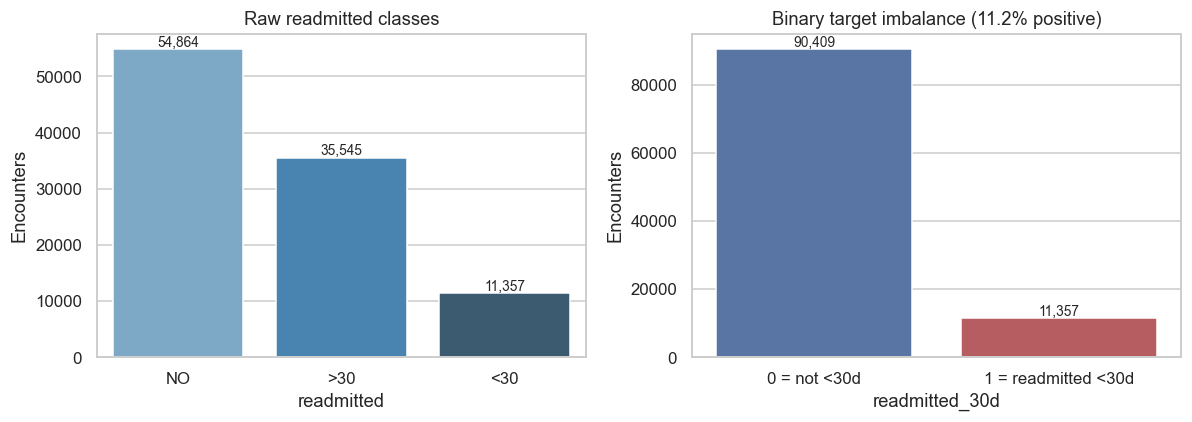

class balance: {0: 0.8884, 1: 0.1116}
imbalance ratio  negative:positive = 8.0 : 1


In [5]:
# 1.3.1 (a): target imbalance
eda = raw.copy()
eda[TARGET] = y_raw

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x='readmitted', data=eda, order=['NO', '>30', '<30'], ax=ax[0], palette='Blues_d')
ax[0].set_title('Raw readmitted classes'); ax[0].set_xlabel('readmitted'); ax[0].set_ylabel('Encounters')
for p in ax[0].patches:
    ax[0].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom', fontsize=9)

counts = eda[TARGET].value_counts().sort_index()
sns.barplot(x=counts.index.map({0: '0 = not <30d', 1: '1 = readmitted <30d'}), y=counts.values,
            ax=ax[1], palette=['#4C72B0', '#C44E52'])
ax[1].set_title(f'Binary target imbalance ({eda[TARGET].mean():.1%} positive)')
ax[1].set_xlabel(TARGET); ax[1].set_ylabel('Encounters')
for p in ax[1].patches:
    ax[1].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

print('class balance:', eda[TARGET].value_counts(normalize=True).round(4).to_dict())
print(f'imbalance ratio  negative:positive = {(1 - eda[TARGET].mean()) / eda[TARGET].mean():.1f} : 1')

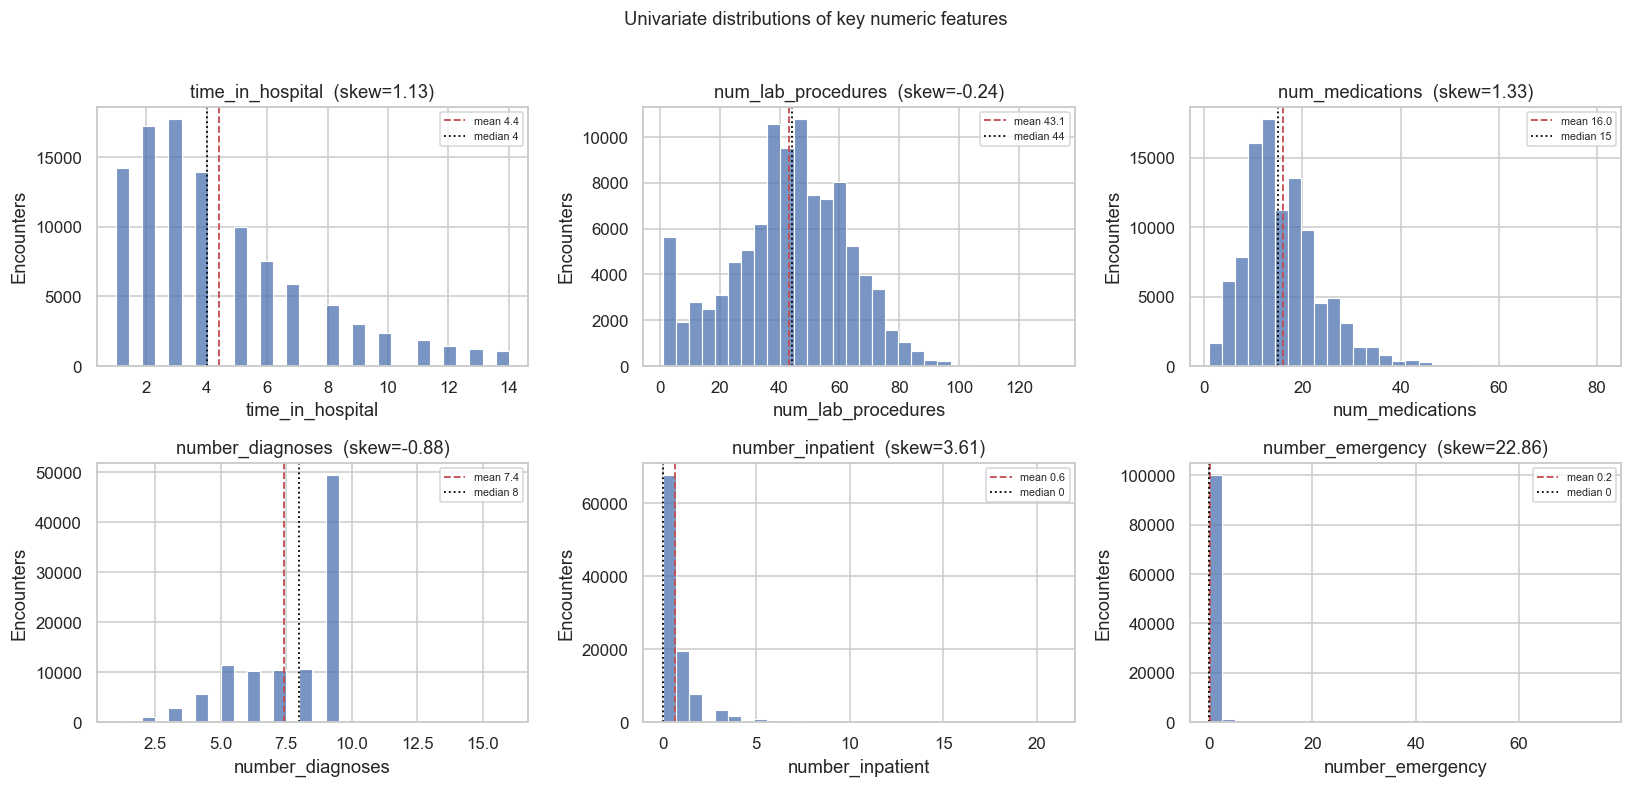

,count,mean,std,min,25%,50%,75%,max,skew
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,1.13
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,-0.24
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,1.33
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,-0.88
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,3.61
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,22.86


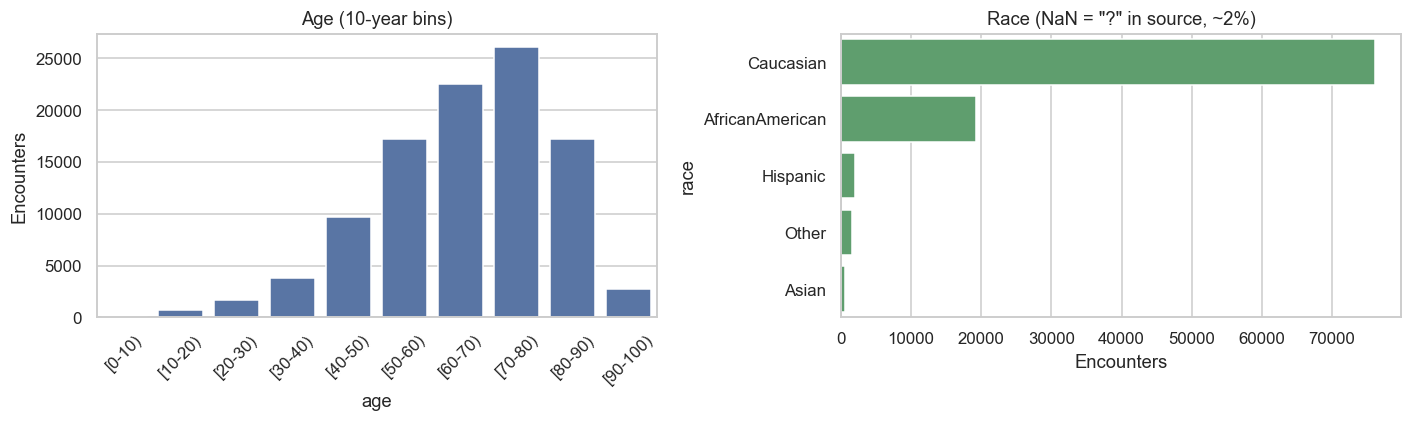

In [6]:
# 1.3.1 (b): >=3 numeric feature distributions
num_feats = ['time_in_hospital', 'num_lab_procedures', 'num_medications',
             'number_diagnoses', 'number_inpatient', 'number_emergency']

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), num_feats):
    sns.histplot(eda[c], bins=30, kde=False, ax=a, color='#4C72B0')
    a.axvline(eda[c].mean(), color='#C44E52', ls='--', lw=1.2, label=f'mean {eda[c].mean():.1f}')
    a.axvline(eda[c].median(), color='black', ls=':', lw=1.2, label=f'median {eda[c].median():.0f}')
    a.set_title(f'{c}  (skew={eda[c].skew():.2f})'); a.set_xlabel(c); a.set_ylabel('Encounters')
    a.legend(fontsize=7)
plt.suptitle('Univariate distributions of key numeric features', y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

display(eda[num_feats].describe().T.round(2).assign(skew=eda[num_feats].skew().round(2)))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(x='age', data=eda, order=sorted(eda['age'].dropna().unique()), ax=ax[0], color='#4C72B0')
ax[0].set_title('Age (10-year bins)'); ax[0].set_ylabel('Encounters'); ax[0].tick_params(axis='x', rotation=45)
sns.countplot(y='race', data=eda, order=eda['race'].value_counts().index, ax=ax[1], color='#55A868')
ax[1].set_title('Race (NaN = "?" in source, ~2%)'); ax[1].set_xlabel('Encounters')
plt.tight_layout(); plt.show()

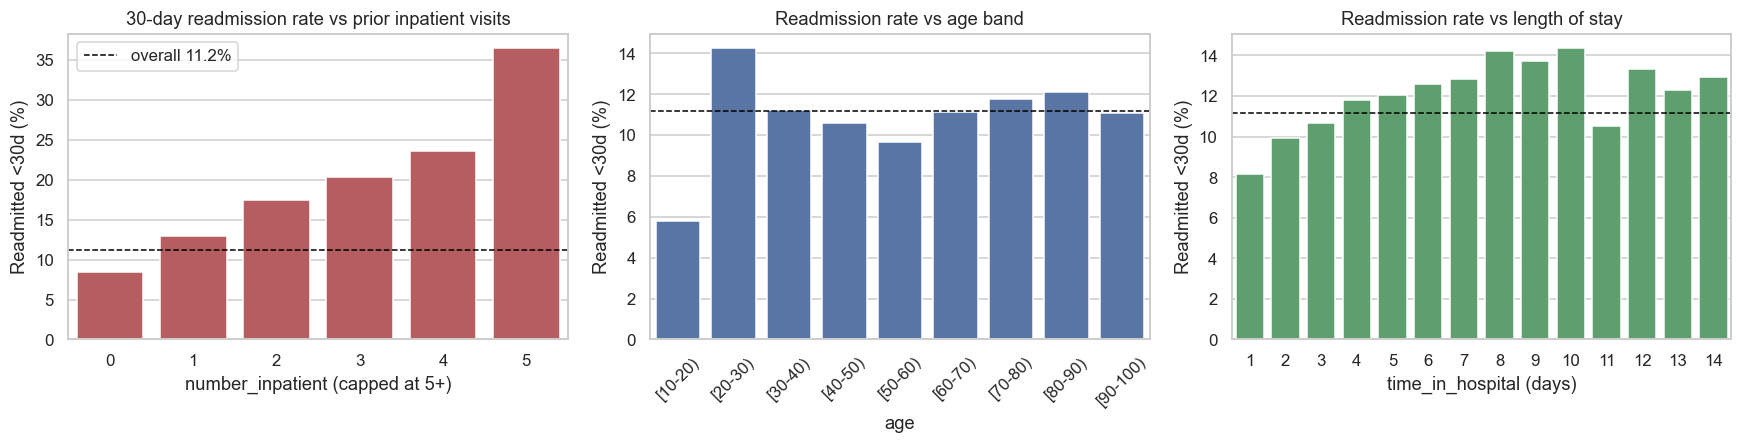

Readmission rate by prior inpatient visits:


,n,readmit_rate_pct
number_inpatient_capped,,
0,67630,8.44
1,19521,12.92
2,7566,17.43
3,3411,20.29
4,1622,23.61
5,2016,36.41


Readmission rate by top discharge dispositions (expired/hospice codes are dropped in 2.1.2):


,n,readmit_rate_pct
discharge_disposition_id,,
1,60234,9.30
2,2128,16.07
3,13954,14.66
5,1184,20.86
6,12902,12.70
11,1642,0.00
18,3691,12.44
22,1993,27.70


Readmission rate by diabetesMed and by medication change:


,n,readmit_rate_pct
diabetesMed,,
No,23403,9.60
Yes,78363,11.63


,n,readmit_rate_pct
change,,
Ch,47011,11.82
No,54755,10.59



Correlation of numeric features with the target:
number_inpatient      0.1651
number_emergency      0.0607
number_diagnoses      0.0495
time_in_hospital      0.0442
num_medications       0.0384
num_lab_procedures    0.0204
Name: readmitted_30d, dtype: float64


In [7]:
# 1.3.2: >=1 bivariate view vs the target
def rate_table(df, col, min_n=200):
    """Readmission rate + support per level of `col` (levels with >= min_n rows)."""
    t = (df.groupby(col)[TARGET].agg(n='size', readmit_rate='mean').query('n >= @min_n').sort_index())
    t['readmit_rate_pct'] = (t['readmit_rate'] * 100).round(2)
    return t

base = eda[TARGET].mean()
ip = eda.assign(number_inpatient_capped=eda['number_inpatient'].clip(upper=5))
tab_ip  = rate_table(ip, 'number_inpatient_capped')
tab_age = rate_table(eda, 'age')
tab_los = rate_table(eda, 'time_in_hospital')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
sns.barplot(x=tab_ip.index.astype(str), y=tab_ip['readmit_rate_pct'], ax=ax[0], color='#C44E52')
ax[0].axhline(base * 100, ls='--', color='black', lw=1, label=f'overall {base:.1%}')
ax[0].set_title('30-day readmission rate vs prior inpatient visits')
ax[0].set_xlabel('number_inpatient (capped at 5+)'); ax[0].set_ylabel('Readmitted <30d (%)'); ax[0].legend()

sns.barplot(x=tab_age.index, y=tab_age['readmit_rate_pct'], ax=ax[1], color='#4C72B0')
ax[1].axhline(base * 100, ls='--', color='black', lw=1)
ax[1].set_title('Readmission rate vs age band'); ax[1].set_xlabel('age'); ax[1].set_ylabel('Readmitted <30d (%)')
ax[1].tick_params(axis='x', rotation=45)

sns.barplot(x=tab_los.index.astype(str), y=tab_los['readmit_rate_pct'], ax=ax[2], color='#55A868')
ax[2].axhline(base * 100, ls='--', color='black', lw=1)
ax[2].set_title('Readmission rate vs length of stay')
ax[2].set_xlabel('time_in_hospital (days)'); ax[2].set_ylabel('Readmitted <30d (%)')
plt.tight_layout(); plt.show()

print('Readmission rate by prior inpatient visits:'); display(tab_ip[['n', 'readmit_rate_pct']])
print('Readmission rate by top discharge dispositions (expired/hospice codes are dropped in 2.1.2):')
display(rate_table(eda, 'discharge_disposition_id', min_n=1000)[['n', 'readmit_rate_pct']].head(10))
print('Readmission rate by diabetesMed and by medication change:')
display(rate_table(eda, 'diabetesMed')[['n', 'readmit_rate_pct']])
display(rate_table(eda, 'change')[['n', 'readmit_rate_pct']])

corr = eda[num_feats + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print('\nCorrelation of numeric features with the target:'); print(corr.round(4))

#### Interpretation (1.3.3)

**Class imbalance and metric choice.** Only **~11.2% of raw encounters** (and ~9% of the cleaned, first-encounter
modelling frame) are positive - roughly **8-10 negatives per positive**. A model that predicts "never readmitted"
scores ~89-91% accuracy while catching zero at-risk patients, so **accuracy is misleading**.
Because the costly error is a **missed readmission (false negative)** - the patient goes home with no follow-up -
the evaluation frame is:

* **Model selection: ROC-AUC** - threshold-independent ranking quality, which is what a risk-ordered
  discharge work-list needs, and it is not inflated by the majority class the way accuracy is.
* **Operational watch: recall** on the positive class - it counts missed readmissions (false negatives)
  directly, the costly error.
* **Reported alongside:** PR-AUC (judged against the ~9% prevalence baseline), precision and F1 to expose the
  precision/recall trade-off, and the confusion matrix at the documented 0.5 operating threshold.
  **Accuracy is never used for selection.**
* **Training-side treatment:** stratified splits and `class_weight='balanced'` / `scale_pos_weight`, so no rows
  are discarded; the threshold sweep in Stage 3 shows how the operating point would be moved for a given
  care-team capacity.

**Unusable and problematic columns.** `weight` is **~97% missing** - no imputation recovers a signal from 3% of
rows, so it is dropped. `payer_code` (~40%) is a billing artefact with no clinical meaning and is dropped.
`medical_specialty` (~49%) is kept because its missingness is itself informative (it tracks the admission route) -
it is handled as an explicit `Missing` category plus top-k grouping. `race` (~2%) is kept and encoded.
`examide` and `citoglipton` are **constant** ("No" everywhere) and several other drugs (e.g. `acetohexamide`,
`troglitazone`, `glimepiride-pioglitazone`) are >99.9% constant - zero variance means zero signal, so `clean()`
removes them. `encounter_id` and `patient_nbr` are identifiers and are excluded from the feature matrix.

**Bivariate findings.**
1. **Prior inpatient visits dominate.** Risk rises monotonically from ~7-8% with no prior inpatient visit to well
   over 25-30% at 3+ prior visits - the strongest single predictor, which motivates `service_utilization`.
2. **Age and length of stay** both correlate positively with risk; `time_in_hospital` is right-skewed, so median
   imputation and scaling matter.
3. **Discharge disposition is a real signal and a label-validity trap.** Transfers to SNF/other facilities readmit
   far more often than routine home discharge, while the **expired/hospice codes {11,13,14,19,20,21}** can *never*
   be readmitted - leaving them in would teach a guaranteed-negative artefact, so those rows are dropped.
4. **Medication context matters:** patients on diabetes medication and those whose regimen changed during the stay
   readmit more often, which justifies `num_med_changes`.
5. **Granularity caveat:** ~23.5% of patients (16,773) contribute more than one encounter, so a row-level split would place
   the same patient in both train and test. Keeping only the **first encounter per patient** is the single most
   important leakage control in this project.

## Stage 2 - Data Preparation [25 marks]

All logic lives in `src/data_prep.py` and is called from here, so the notebook and `src/train.py` share one
implementation:

| function | sub-tasks |
|---|---|
| `clean(df)` | 2.1.1 missing/invalid values + unusable & zero-variance columns, 2.1.2 patient dedup + invalid records, 2.1.3 target creation |
| `engineer_features(df)` | 2.2.1 ICD-9 grouping, 2.2.2 age midpoint / service utilisation / med-change count / specialty top-k |
| `get_feature_lists(df)` / `build_preprocessor(numeric, categorical)` | 2.3.1 scaling + encoding, 2.3.2 one unfitted ColumnTransformer |
| `get_splits(df)` | 2.4.1 stratified train/val/test split created first (val carved out of train) |

### Stage 2.1 - Data Cleaning [6 marks]

**2.1.1** missing-value & invalid-value handling [2] &nbsp;&nbsp; **2.1.2** patient dedup + invalid records [2]
&nbsp;&nbsp; **2.1.3** target creation & validation [2]

In [8]:
clean_df = dp.clean(raw)

print('cleaned shape:', clean_df.shape)
print('columns dropped by clean():')
for k, v in getattr(dp.clean, 'dropped_', {}).items():
    print(f'  {k:<14} {v}')
clean_df.head(3)

cleaned shape: (69973, 35)
columns dropped by clean():
  unusable       ['encounter_id', 'patient_nbr', 'weight', 'payer_code', 'examide', 'citoglipton', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'glimepiride-pioglitazone', 'acetohexamide', 'troglitazone', 'tolbutamide']
  constant       []
  near_constant  ['miglitol', 'tolazamide', 'glipizide-metformin']
  label          ['readmitted']


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,glipizide,glyburide,pioglitazone,rosiglitazone,acarbose,insulin,glyburide-metformin,change,diabetesMed,readmitted_30d
8,Caucasian,Female,[80-90),2,1,4,13,NaN,68,2,28,0,0,0,398,427,38,8,NaN,NaN,No,No,No,No,No,Steady,No,No,No,No,Steady,No,Ch,Yes,0
9,Caucasian,Female,[90-100),3,3,4,12,InternalMedicine,33,3,18,0,0,0,434,198,486,8,NaN,NaN,No,No,No,No,No,No,No,No,Steady,No,Steady,No,Ch,Yes,0
4,Caucasian,Male,[40-50),1,1,7,1,NaN,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,Steady,No,No,No,No,Steady,No,Ch,Yes,0


In [9]:
# 2.1.3 validation of the cleaned modelling frame
expired = list(getattr(cfg, 'EXPIRED_HOSPICE_DISPOSITIONS', [11, 13, 14, 19, 20, 21]))
# clean() preserves the original index, so every surviving row can be traced back to `raw`
pat_clean = raw.loc[clean_df.index, 'patient_nbr']
disp_clean = raw.loc[clean_df.index, 'discharge_disposition_id']

print(f'cleaned shape        : {clean_df.shape}   (expected ~69,973 rows)')
print(f'rows removed         : {raw.shape[0] - clean_df.shape[0]:,} of {raw.shape[0]:,}')
print(f'unique patients      : {pat_clean.nunique():,}')
print(f'one row per patient  : {pat_clean.is_unique}')
print(f'expired/hospice left : {disp_clean.isin(expired).sum()}')
print(f'weight dropped       : {"weight" not in clean_df.columns}')
print(f'raw label dropped    : {"readmitted" not in clean_df.columns}')

print(f'\ntarget balance:\n{clean_df[TARGET].value_counts()}')
print(f'\npositive rate        : {clean_df[TARGET].mean():.2%}   (expected ~9%)')
print(f'imbalance ratio      : {(1 - clean_df[TARGET].mean()) / clean_df[TARGET].mean():.1f} : 1')

assert pat_clean.is_unique, 'patient-level leakage: duplicate patients remain'
assert not disp_clean.isin(expired).any(), 'expired/hospice rows remain -> invalid labels'
assert 'weight' not in clean_df.columns, 'weight (~97% missing) should be dropped'
assert set(clean_df[TARGET].unique()) == {0, 1}, 'target must be binary 0/1'
print('\nall cleaning assertions passed.')

print('\nremaining missing values after cleaning:')
m = clean_df.isna().mean().mul(100).round(2)
display(m[m > 0].sort_values(ascending=False).to_frame('missing_pct'))

cleaned shape        : (69973, 35)   (expected ~69,973 rows)
rows removed         : 31,793 of 101,766
unique patients      : 69,973
one row per patient  : True
expired/hospice left : 0
weight dropped       : True
raw label dropped    : True

target balance:
readmitted_30d
0    63696
1     6277
Name: count, dtype: int64

positive rate        : 8.97%   (expected ~9%)
imbalance ratio      : 10.1 : 1

all cleaning assertions passed.

remaining missing values after cleaning:


,missing_pct
max_glu_serum,95.22
A1Cresult,81.64
medical_specialty,48.07
race,2.74
diag_3,1.75
diag_2,0.42
diag_1,0.01


### Stage 2.2 - Feature Engineering [8 marks]

**2.2.1** ICD-9 diagnosis grouping into clinical categories [4] &nbsp;&nbsp;
**2.2.2** additional engineered features, justified [4]

In [10]:
fe = dp.engineer_features(clean_df)

created = [c for c in getattr(dp.engineer_features, 'created_', []) if c in fe.columns]
print('engineered columns:', created)
print('frame shape:', fe.shape)
fe[created].head(10)

engineered columns: ['diag_1', 'diag_2', 'diag_3', 'age', 'service_utilization', 'num_med_changes', 'num_meds_prescribed', 'medical_specialty']
frame shape: (69973, 38)


,diag_1,diag_2,diag_3,age,service_utilization,num_med_changes,num_meds_prescribed,medical_specialty
8,Circulatory,Circulatory,Other,85.0,0,0,2,Missing
9,Circulatory,Neoplasms,Respiratory,95.0,0,0,2,InternalMedicine
4,Neoplasms,Neoplasms,Diabetes,45.0,0,0,2,Missing
10,Diabetes,Circulatory,Injury,45.0,0,0,1,Missing
5,Circulatory,Circulatory,Diabetes,55.0,0,0,1,Missing
11,Neoplasms,Other,Neoplasms,65.0,0,1,2,Missing
12,Circulatory,Diabetes,Diabetes,45.0,1,2,3,Family/GeneralPractice
13,Circulatory,Circulatory,Circulatory,85.0,0,0,1,Family/GeneralPractice
6,Circulatory,Circulatory,Other,65.0,0,0,3,Missing
14,Respiratory,Injury,Genitourinary,65.0,0,0,1,Missing


diagnosis cardinality before -> after grouping (grouped in place, column names unchanged):
  diag_1:  716 raw codes  ->  10 clinical categories
  diag_2:  748 raw codes  ->  10 clinical categories
  diag_3:  789 raw codes  ->  10 clinical categories

mapping spot-check: {'250.83': 'Diabetes', '428': 'Circulatory', '486': 'Respiratory', '715': 'Musculoskeletal', '820': 'Injury', 'V57': 'Other', nan: 'Missing'}

primary diagnosis (diag_1) distribution and readmission rate:


,n,readmit_rate_pct
diag_1,,
Circulatory,21384,9.67
Other,12122,8.97
Respiratory,9486,7.28
Digestive,6487,8.02
Diabetes,5748,9.12
Injury,4694,10.78
Musculoskeletal,4064,8.39
Genitourinary,3440,8.98
Neoplasms,2538,9.06


age mapping spot-check: {'[80-90)': 85.0, '[90-100)': 95.0, '[40-50)': 45.0, '[50-60)': 55.0}
mean of engineered features by class (0 = not readmitted <30d, 1 = readmitted):


readmitted_30d,class_0,class_1,lift
age,65.205,67.829,1.040
service_utilization,0.533,0.827,1.552
num_med_changes,0.258,0.296,1.147
num_meds_prescribed,1.185,1.224,1.033


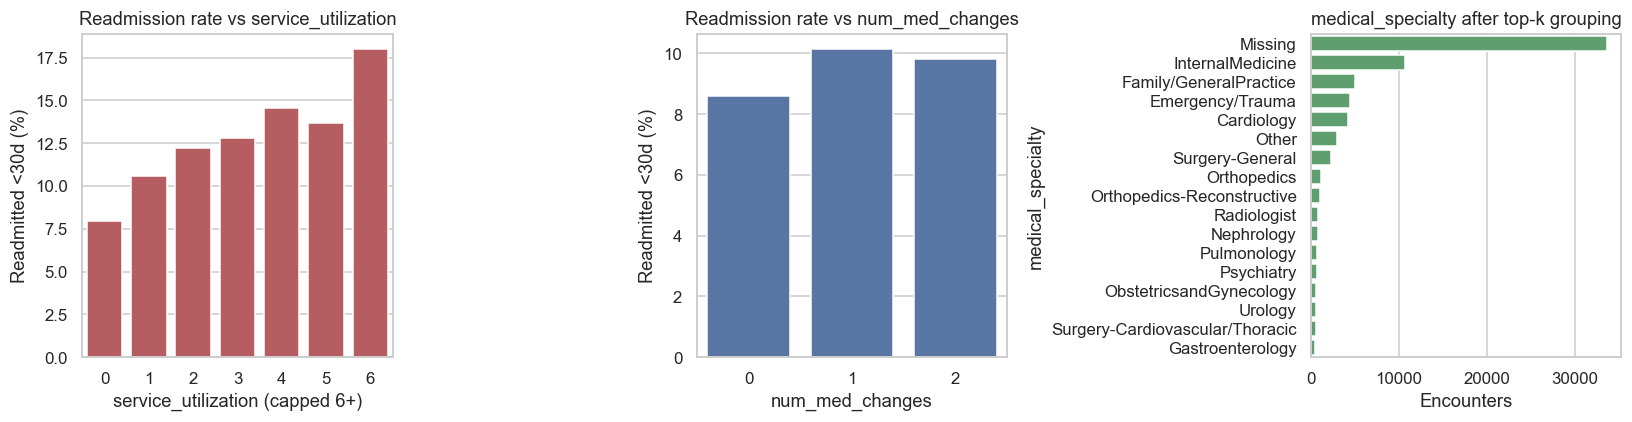

In [11]:
# 2.2.1 sanity-check the ICD-9 grouping: cardinality collapse + rate per category
print('diagnosis cardinality before -> after grouping (grouped in place, column names unchanged):')
for c in ['diag_1', 'diag_2', 'diag_3']:
    print(f'  {c}: {raw[c].nunique():>4} raw codes  ->  {fe[c].nunique()} clinical categories')
print('\nmapping spot-check:', {code: dp.map_icd9(code) for code in ['250.83', '428', '486', '715', '820', 'V57', np.nan]})

print('\nprimary diagnosis (diag_1) distribution and readmission rate:')
display(fe.groupby('diag_1')[TARGET]
          .agg(n='size', readmit_rate='mean')
          .assign(readmit_rate_pct=lambda t: (t.readmit_rate * 100).round(2))
          .drop(columns='readmit_rate').sort_values('n', ascending=False))

# 2.2.2 age band -> numeric midpoint (in place)
print('age mapping spot-check:', dict(zip(clean_df['age'].head(5), fe['age'].head(5))))

# 2.2.2 do the engineered features actually separate the classes?
eng_num = ['age', 'service_utilization', 'num_med_changes', 'num_meds_prescribed']
print('mean of engineered features by class (0 = not readmitted <30d, 1 = readmitted):')
display(fe.groupby(TARGET)[eng_num].mean().round(3).T
          .rename(columns={0: 'class_0', 1: 'class_1'})
          .assign(lift=lambda t: (t.class_1 / t.class_0).round(3)))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
su = fe.assign(su=fe['service_utilization'].clip(upper=6))
r1 = su.groupby('su')[TARGET].mean().mul(100)
sns.barplot(x=r1.index.astype(str), y=r1.values, ax=ax[0], color='#C44E52')
ax[0].set_title('Readmission rate vs service_utilization')
ax[0].set_xlabel('service_utilization (capped 6+)'); ax[0].set_ylabel('Readmitted <30d (%)')

r2 = fe.groupby('num_med_changes')[TARGET].agg(['size', 'mean'])
r2 = r2[r2['size'] >= 100]
sns.barplot(x=r2.index.astype(str), y=r2['mean'].mul(100).values, ax=ax[1], color='#4C72B0')
ax[1].set_title('Readmission rate vs num_med_changes')
ax[1].set_xlabel('num_med_changes'); ax[1].set_ylabel('Readmitted <30d (%)')

sns.countplot(y='medical_specialty', data=fe, color='#55A868',
              order=fe['medical_specialty'].value_counts().index, ax=ax[2])
ax[2].set_title('medical_specialty after top-k grouping'); ax[2].set_xlabel('Encounters')
plt.tight_layout(); plt.show()


#### Feature-engineering justification (2.2.1 - 2.2.2)

All transforms are applied **in place** (the column keeps its name), so the engineered frame has exactly the schema
that the provided `src/generate_current_batch.py` shifts in Stage 4 (`age + 10`, `diag_1 -> 'Circulatory'`).
Derived flags that the generator would not recompute (e.g. a `number_inpatient > 0` flag) are deliberately not
created, so a simulated batch can never carry a stale engineered value.

| feature | definition | why it is justified |
|---|---|---|
| `diag_1/2/3` (grouped) | ICD-9 code → clinical chapter (Circulatory, Respiratory, Digestive, Diabetes, Injury, Genitourinary, Musculoskeletal, Neoplasms, Other, Missing) - Strack et al. (2014) grouping | collapses ~700-800 sparse codes per column into 10 clinically coherent, transferable levels; prevents one-hot explosion and unstable rare levels |
| `age` (midpoint) | `[70-80)` → 75 | `age` is an *ordered* bin; a numeric midpoint preserves that order in one scaled column instead of ten unordered dummies |
| `service_utilization` | `number_outpatient + number_emergency + number_inpatient` | EDA showed prior utilisation is the strongest signal; one dense intensity measure captures "frequent flyer" patients |
| `num_med_changes` | count of `cfg.MED_COLS` equal to `Up`/`Down` | regimen titration signals an uncontrolled patient; compresses 15 sparse drug columns into one interpretable count |
| `num_meds_prescribed` | count of `cfg.MED_COLS` ≠ `No` | therapy complexity / polypharmacy proxy |
| `medical_specialty` (top-k) | fixed list of 15 specialties + `Other` + `Missing` | 72 levels, ~49% missing; the shortlist is **hard-coded, not learned from the frame**, so grouping is deterministic and leakage-free, and `Missing` is retained because missingness tracks the admission route |


### Stage 2.3 - Feature Transformation [5 marks]

**2.3.1** numeric scaling & categorical encoding [3] &nbsp;&nbsp;
**2.3.2** leakage-safe ColumnTransformer assembly - built but **not fitted** [2]

In [12]:
numeric, categorical = dp.get_feature_lists(fe)
print(f'numeric ({len(numeric)}):', numeric)
print(f'\ncategorical ({len(categorical)}):', categorical)
print(f'\nexcluded from features: {TARGET} + identifiers {dp.LEAKY_COLS}')

preprocessor = dp.build_preprocessor(numeric, categorical)
preprocessor

numeric (12): ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'service_utilization', 'num_med_changes', 'num_meds_prescribed']

categorical (25): ['race', 'gender', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'medical_specialty', 'diag_1', 'diag_2', 'diag_3', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'glipizide', 'glyburide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'insulin', 'glyburide-metformin', 'change', 'diabetesMed']

excluded from features: readmitted_30d + identifiers ['encounter_id', 'patient_nbr', 'readmitted']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'time_in_hospital',
                                  'num_lab_procedures', 'num_procedures',
                                  'num_medications', 'number_outpatient',
                                  'number_emergency', 'number_inpatient',
                                  'number_diagnoses', 'service_utilization',
                                  'num_med_changes', 'num_meds_prescribed'])...
                                  'discharge_disposition_id',
                                  'admission_source_id', 'medical_specialty',
                                  'diag_1', 'diag_2', 'diag_3', 'max_glu_serum',
                                  'A1Cresult', 'metformin', 'repaglinide',
                                  'nateglinide', 'chlorpropamide',
                                  'glimepiride', 'glipizide', 'glyburide',
                                  'pioglitazone', 'rosiglitazone', 'acarbose',
                                  'insulin', 'glyburide-metformin', 'change',
                                  'diabetesMed'])],
                  verbose_feature_names_out=False)

In [13]:
# 2.3.2 structure check - ONE ColumnTransformer, assembled and NOT yet fitted
for name, trans, cols in preprocessor.transformers:
    print(f'{name:<4} | steps={[s[0] for s in trans.steps]} | n_cols={len(cols)}')
print('\nnumeric steps  : median SimpleImputer -> StandardScaler')
print('categorical    : constant impute ("Missing") -> OneHotEncoder(handle_unknown="ignore")')

try:
    check_is_fitted(preprocessor)
    print('\nWARNING: preprocessor is already fitted - leakage risk!')
except NotFittedError:
    print('\nconfirmed UNFITTED: no statistics learned yet, so nothing from val/test can leak in.')

num  | steps=['impute', 'scale'] | n_cols=12
cat  | steps=['to_str', 'impute', 'onehot'] | n_cols=25

numeric steps  : median SimpleImputer -> StandardScaler
categorical    : constant impute ("Missing") -> OneHotEncoder(handle_unknown="ignore")

confirmed UNFITTED: no statistics learned yet, so nothing from val/test can leak in.


### Stage 2.4 - Validation & Splitting [6 marks]

**2.4.1** stratified train/validation/test split created **first** [3] &nbsp;&nbsp;
**2.4.2** leakage-safe fit-on-train + class-balance check [3]

In [14]:
# 2.4.1 STRATIFIED split created BEFORE any fitting (validation carved out of the train split)
X_train, X_val, X_test, y_train, y_val, y_test = dp.get_splits(fe)

for name, Xs, ys in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    print(f'{name:<6} n={len(Xs):>6,} ({len(Xs)/len(fe):5.1%})  positives={int(ys.sum()):>5,}  rate={ys.mean():.4f}')
print(f'{"full":<6} n={len(fe):>6,}            positives={int(fe[TARGET].sum()):>5,}  rate={fe[TARGET].mean():.4f}')
print('\nfeature columns in X:', X_train.shape[1])

train  n=44,782 (64.0%)  positives=4,018  rate=0.0897


val    n=11,196 (16.0%)  positives=1,004  rate=0.0897
test   n=13,995 (20.0%)  positives=1,255  rate=0.0897
full   n=69,973            positives=6,277  rate=0.0897

feature columns in X: 37


In [15]:
# 2.4.2 fit the preprocessor on TRAIN ONLY, then transform val/test
Xtr = preprocessor.fit_transform(X_train)      # <-- the ONLY fit call in the whole notebook
Xva = preprocessor.transform(X_val)
Xte = preprocessor.transform(X_test)

Xtr, Xva, Xte = np.asarray(Xtr), np.asarray(Xva), np.asarray(Xte)
print('transformed shapes -> train', Xtr.shape, '| val', Xva.shape, '| test', Xte.shape)

try:
    feature_names = list(preprocessor.get_feature_names_out())
except Exception:
    feature_names = [f'f{i}' for i in range(Xtr.shape[1])]
print(f'\nraw feature columns : {X_train.shape[1]}  ->  transformed features: {Xtr.shape[1]}')
print('first 15 transformed feature names:', feature_names[:15])

transformed shapes -> train (44782, 172) | val (11196, 172) | test (13995, 172)

raw feature columns : 37  ->  transformed features: 172
first 15 transformed feature names: ['age', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'service_utilization', 'num_med_changes', 'num_meds_prescribed', 'race_AfricanAmerican', 'race_Asian', 'race_Caucasian']


In [16]:
# ---- leakage & class-balance audit -------------------------------------------------
summary = pd.DataFrame({
    'rows':      [len(X_train), len(X_val), len(X_test)],
    'share':     [len(X_train) / len(fe), len(X_val) / len(fe), len(X_test) / len(fe)],
    'positives': [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    'pos_rate':  [y_train.mean(), y_val.mean(), y_test.mean()],
    'features':  [Xtr.shape[1], Xva.shape[1], Xte.shape[1]],
}, index=['train', 'val', 'test'])
summary.loc['FULL'] = [len(fe), 1.0, int(fe[TARGET].sum()), fe[TARGET].mean(), Xtr.shape[1]]
display(summary.assign(share=lambda t: (t['share'] * 100).round(1),
                       pos_rate=lambda t: (t['pos_rate'] * 100).round(2)))

full_rate = fe[TARGET].mean()
print('class ratio preserved (within 0.5pp of the full frame):',
      all(abs(r - full_rate) < 0.005 for r in [y_train.mean(), y_val.mean(), y_test.mean()]))

# no patient appears in more than one split (indices still map back to the raw frame)
tr = set(raw.loc[X_train.index, 'patient_nbr']); va = set(raw.loc[X_val.index, 'patient_nbr'])
te = set(raw.loc[X_test.index, 'patient_nbr'])
print('patient overlap train/val:', len(tr & va), '| train/test:', len(tr & te), '| val/test:', len(va & te))

# identifiers never reach the model
print('identifier columns inside X:', [c for c in dp.LEAKY_COLS if c in X_train.columns], '(must be empty)')

# the preprocessor saw TRAIN rows only: its imputer medians must equal the TRAIN medians
num_cols = preprocessor.transformers_[0][2]
fitted_medians = pd.Series(preprocessor.named_transformers_['num'].named_steps['impute'].statistics_, index=num_cols)
print('imputer learned from TRAIN only:',
      np.allclose(fitted_medians.values, X_train[num_cols].median().values, equal_nan=True))

assert len(tr & va) == len(tr & te) == len(va & te) == 0, 'patient-level leakage across splits'
assert len(X_train) + len(X_val) + len(X_test) == len(fe), 'split sizes do not reconcile'
assert Xtr.shape[1] == Xva.shape[1] == Xte.shape[1], 'inconsistent feature counts across splits'
assert not np.isnan(Xtr.astype(float)).any(), 'NaNs remain after preprocessing'
assert not [c for c in dp.LEAKY_COLS if c in X_train.columns], 'identifier leaked into X'
print('\nall splitting / leakage assertions passed.')

,rows,share,positives,pos_rate,features
train,44782.0,64.0,4018.0,8.97,172.0
val,11196.0,16.0,1004.0,8.97,172.0
test,13995.0,20.0,1255.0,8.97,172.0
FULL,69973.0,100.0,6277.0,8.97,172.0


class ratio preserved (within 0.5pp of the full frame): True
patient overlap train/val: 0 | train/test: 0 | val/test: 0
identifier columns inside X: [] (must be empty)
imputer learned from TRAIN only: True

all splitting / leakage assertions passed.


In [17]:
# Persist the prepared artefacts for Stage 3 (modelling) so the pipeline stays reproducible
out_dir = getattr(cfg, 'PROCESSED_DIR', 'data/processed')
os.makedirs(out_dir, exist_ok=True)

clean_df.to_csv(os.path.join(out_dir, 'clean.csv'), index=False)
fe.to_csv(os.path.join(out_dir, 'features.csv'), index=False)
for name, Xs, ys in [('train', X_train, y_train), ('val', X_val, y_val), ('test', X_test, y_test)]:
    Xs.assign(**{TARGET: ys}).to_csv(os.path.join(out_dir, f'{name}.csv'), index=False)

try:
    import joblib
    joblib.dump(preprocessor, os.path.join(out_dir, 'preprocessor_fitted_on_train.joblib'))
except Exception as e:
    print('joblib dump skipped:', e)

print('saved to', out_dir, ':', sorted(os.listdir(out_dir)))

saved to data/processed : ['clean.csv', 'features.csv', 'preprocessor_fitted_on_train.joblib', 'test.csv', 'train.csv', 'val.csv']


### Stage 1.4 (condensed) - Methodology & leakage-safety record

**Leakage controls, in execution order.** (1) First encounter per patient only, so no patient spans two splits.
(2) Expired/hospice discharges removed before the label is used, so no structurally impossible negatives.
(3) Target derived from `readmitted`, which is then dropped. (4) Identifiers (`encounter_id`, `patient_nbr`)
excluded from `X` by `get_feature_lists` / `get_splits`. (5) Stratified split created **first**; the single
`ColumnTransformer` is `fit` on **train only** and merely `transform`s validation/test - verified above by
comparing the fitted imputer medians with the train medians. (6) `handle_unknown='ignore'` so categories unseen in
training cannot break inference. (7) The specialty shortlist is hard-coded, not learned from the frame.

**Evaluation frame carried into Stage 3.** ROC-AUC on the validation split selects the model; recall is the
operational watch; PR-AUC, precision and F1 are reported alongside; accuracy is shown only as the
counterexample. The 0.5 threshold is the documented operating point and the test split is touched once,
after registration. Imbalance is handled with class weighting rather than by discarding data.

**End-to-end MLOps path.** `data/` raw → versioned prep functions in `src/data_prep.py` (shared by this notebook
and `src/train.py`) → tracked experiments → registered model with the fitted preprocessor bundled, so training and
serving share one transformation → served behind an API → monitored for feature drift (Evidently) and prediction drift (PSI), with scheduled retraining on refreshed, re-deduplicated data.